In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import numpy as np
import duckdb as ddb

supply_data = pd.read_csv('data/supply_data.csv', parse_dates=['date_mpt_he'])
print(supply_data.info())
print(supply_data.isna().any(axis=1).sum())

full_range = pd.date_range(supply_data['date_mpt_he'].min(), supply_data['date_mpt_he'].max(), freq='h')
gap = full_range.difference(supply_data['date_mpt_he'])
print(gap)

<class 'pandas.DataFrame'>
RangeIndex: 6443989 entries, 0 to 6443988
Data columns (total 6 columns):
 #   Column            Dtype         
---  ------            -----         
 0   date_mpt_he       datetime64[us]
 1   asset_short_name  str           
 2   volume            float64       
 3   max_capability    float64       
 4   fuel_type         str           
 5   sub_fuel_type     str           
dtypes: datetime64[us](1), float64(2), str(3)
memory usage: 295.0 MB
None
0
DatetimeIndex(['2023-03-12 03:00:00', '2024-03-10 03:00:00',
               '2025-03-09 03:00:00', '2026-03-08 03:00:00'],
              dtype='datetime64[us]', freq=None)


#### Maximum Capability
Maximum capability for each fuel type is computed by first taking the maximum capability of each asset per day. That is then used to sum up to maximum capability for each fuel type.

In [36]:
asset_max_cap = ddb.sql(
    '''
    select
        date(date_mpt_he - interval 1 hour) as date,
        asset_short_name,
        max(max_capability) as max_cap,
        fuel_type
    from
        supply_data
    group by
        date,
        asset_short_name,
        fuel_type
    order by
        date,
        max_cap desc
    ''')
print(asset_max_cap)
s = asset_max_cap.df()
print(len(s))
print(s['max_cap'].describe())

┌────────────┬──────────────────┬─────────┬───────────┐
│    date    │ asset_short_name │ max_cap │ fuel_type │
│    date    │     varchar      │ double  │  varchar  │
├────────────┼──────────────────┼─────────┼───────────┤
│ 2023-01-01 │ EGC1             │   868.0 │ GAS       │
│ 2023-01-01 │ SCL1             │   510.0 │ GAS       │
│ 2023-01-01 │ SCR6             │   497.0 │ GAS       │
│ 2023-01-01 │ JOF1             │   474.0 │ GAS       │
│ 2023-01-01 │ GN3              │   466.0 │ DUAL FUEL │
│ 2023-01-01 │ TVS1             │   465.0 │ SOLAR     │
│ 2023-01-01 │ KH3              │   463.0 │ GAS       │
│ 2023-01-01 │ GN2              │   420.0 │ COAL      │
│ 2023-01-01 │ SD6              │   401.0 │ GAS       │
│ 2023-01-01 │ SH1              │   400.0 │ GAS       │
│     ·      │  ·               │      ·  │  ·        │
│     ·      │  ·               │      ·  │  ·        │
│     ·      │  ·               │      ·  │  ·        │
│ 2023-02-26 │ CLY1             │    41.0 │ SOLA

        date  daily_fuel_max_cap       fuel_type
0 2023-01-01             10894.0             GAS
1 2023-01-01              3618.0            WIND
2 2023-01-01              1138.0           SOLAR
3 2023-01-01               894.0           HYDRO
4 2023-01-01               820.0            COAL
5 2023-01-01               466.0       DUAL FUEL
6 2023-01-01               444.0           OTHER
7 2023-01-01                70.0  ENERGY STORAGE
8 2023-01-02             10894.0             GAS
9 2023-01-02              3618.0            WIND


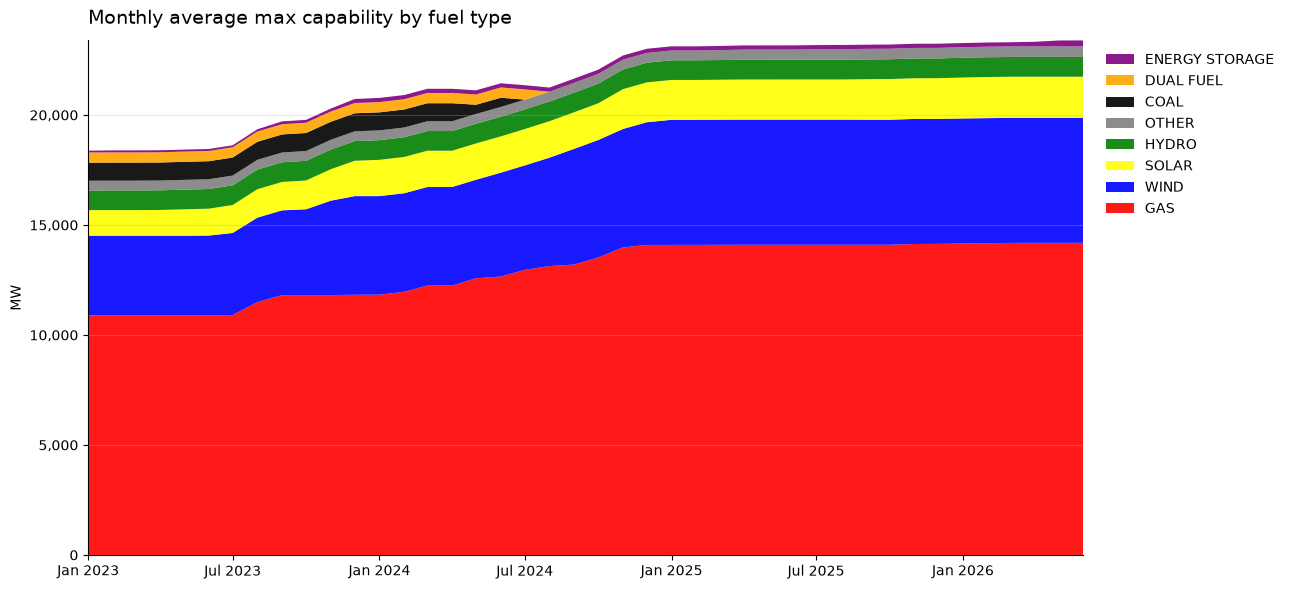

In [55]:
max_cap = ddb.sql('''
    with asset_max_cap as (
            select
                date(date_mpt_he - interval 1 hour) as date,
                asset_short_name,
                max(max_capability) as asset_max_cap,
                fuel_type
            from
                supply_data
            group by
                date,
                asset_short_name,
                fuel_type
            )
    select
        date,
        sum(asset_max_cap) as daily_fuel_max_cap,
        fuel_type
    from
        asset_max_cap
    group by
        date,
        fuel_type
    order by
        date,
        daily_fuel_max_cap desc
''').df()
print(max_cap.head(10))


########## PLOT ################
# Daily -> monthly average, one column per fuel
pivot = (
    max_cap.assign(date=pd.to_datetime(max_cap['date']))
    .pivot(index='date', columns='fuel_type', values='daily_fuel_max_cap')
    .resample('MS').mean()
    .fillna(0)
)

# Largest fuel at the bottom of the stack
pivot = pivot[pivot.mean().sort_values(ascending=False).index]

colors = {
    'GAS': 'red',
    'WIND': 'blue',
    'SOLAR': 'yellow',
    'HYDRO': 'green',
    'COAL': 'black',
    'DUAL FUEL': 'orange',
    'ENERGY STORAGE': 'purple',
    'OTHER': 'gray',
}

fig, ax = plt.subplots(figsize=(13, 6))
ax.stackplot(pivot.index, pivot.T.values,
             labels=pivot.columns,
             colors=[colors.get(c, '#cccccc') for c in pivot.columns],
             alpha=0.9)

ax.set_title('Monthly average max capability by fuel type', fontsize=14, loc='left', pad=12)
ax.set_ylabel('MW')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set_xlim(pivot.index.min(), pivot.index.max())
ax.margins(y=0)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc='upper left',
          bbox_to_anchor=(1.01, 1), frameon=False)

plt.tight_layout()
plt.show()